# StockSight — Results on **Real Market Data**
### Deep-learning option pricing + news-augmented stock prediction

This notebook presents the project's results using **only real market data** — no synthetic
datasets. It covers:

- **Objectives 1–4** on **real NSE option contracts** (NSE F&O Bhavcopy settlement data).
- **Stock-movement prediction** fusing **real `.NS` prices** with **real news** (Marketaux for
  Indian names, Finnhub for US) via cross / co / co+cross and patch co-attention.
- **Reference-paper reproductions**: Shvimer & Zhu (2024) hybrid option pricing, and Zhang et al.
  (2026) patch-based co-attention.

**Objectives**

| # | Objective | Model |
|---|---|---|
| 1 | Evaluate classical **Black–Scholes** vs observed market prices | `black_scholes_call` |
| 2 | **Deep-learning volatility** σ_DL = f_θ(X) | `VolatilityNet` |
| 3 | **Hybrid** C = BS(S,K,T,r, σ_DL) | differentiable BS + `VolatilityNet` |
| 4 | **Residual learning** C = C_BS + Ê | `ResidualOptionANN` |

> Note: real-news free tiers return sparse coverage, so the news-fusion results are noisier than a
> controlled benchmark would be. We report the real numbers as-is.


## 0. Setup

In [1]:
import sys, os, io, contextlib, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
ROOT = os.getcwd()
if ROOT not in sys.path: sys.path.insert(0, ROOT)
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
np.random.seed(42)
ASSETS = "outputs/results_assets"; os.makedirs(ASSETS, exist_ok=True)
class quiet(contextlib.AbstractContextManager):
    def __enter__(self):
        self._b=io.StringIO(); self._r=contextlib.redirect_stdout(self._b); self._r.__enter__(); return self
    def __exit__(self,*a): self._r.__exit__(*a); return False
print("Setup complete:", ROOT)

Setup complete: C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project


## 1. Real dataset — NSE option contracts (F&O Bhavcopy)

`src/real_options.py` downloads NSE's official end-of-day **F&O Bhavcopy** via `jugaad-data` and
builds a clean call-option dataset: real **spot** (`UndrlygPric`), real **strikes**, real
**settlement prices**, filtered for liquidity and no-arbitrage bounds.

In [2]:
from src.real_options import build_option_dataset
from src.pricing import implied_volatility

real = build_option_dataset("RELIANCE", days_back=8, min_volume=1)
print("Real RELIANCE call contracts:", len(real),
      "| dates", real['TradDt'].min().date(), "->", real['TradDt'].max().date())
display(real[["TradDt","XpryDt","S","K","moneyness","T","sigma_hist","C_market","volume","open_interest"]].head())
display(real[["S","K","moneyness","T","sigma_hist","C_market","volume"]].describe().round(3))

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

Real RELIANCE call contracts: 486 | dates 2026-10-22 -> 2026-11-02


C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

,TradDt,XpryDt,S,K,moneyness,T,sigma_hist,C_market,volume,open_interest
0,2026-11-02,2026-12-29,1299.99,1260.0,1.031738,0.156164,0.312027,58.80,2029,320500
1,2026-11-02,2026-11-23,1299.99,1440.0,0.902771,0.057534,0.312027,1.20,4835,634500
2,2026-11-02,2026-11-23,1299.99,1460.0,0.890404,0.057534,0.312027,1.20,54,22500
3,2026-11-02,2026-12-29,1299.99,1270.0,1.023614,0.156164,0.312027,51.70,358,57500
4,2026-11-02,2026-12-29,1299.99,1280.0,1.015617,0.156164,0.312027,48.85,1042,139000


,S,K,moneyness,T,sigma_hist,C_market,volume
count,486.000,486.000,486.000,486.000,486.000,486.000,486.000
mean,1189.912,1257.325,0.954,0.093,0.222,35.570,5109.251
std,37.443,118.485,0.089,0.057,0.029,43.360,12848.145
min,1158.020,1000.000,0.762,0.011,0.209,0.010,1.000
25%,1164.880,1170.000,0.892,0.066,0.211,3.650,87.500
50%,1180.430,1260.000,0.949,0.074,0.211,18.250,662.500
75%,1196.220,1340.000,1.010,0.156,0.217,53.812,3892.250
max,1299.990,1520.000,1.226,0.244,0.312,243.500,176350.000


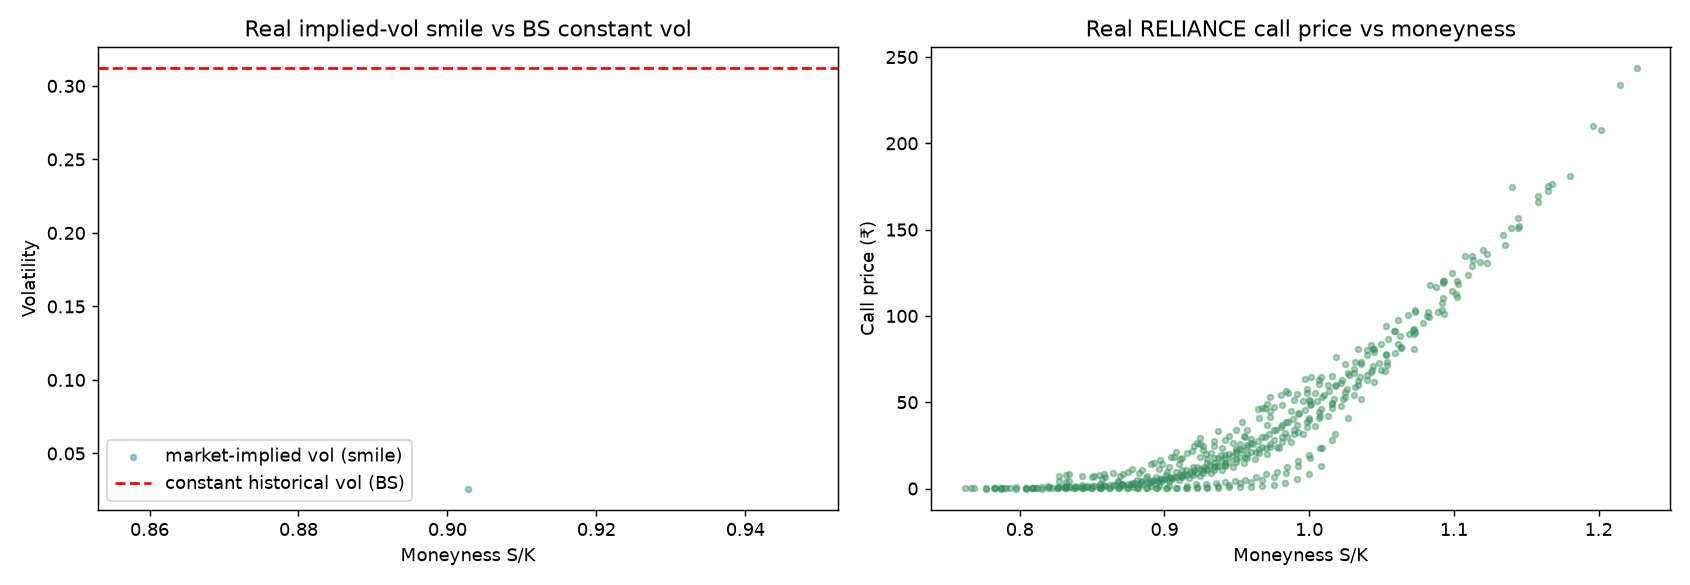

In [3]:
# Real implied-vol SMILE: market-implied vol varies with moneyness, but BS assumes one constant vol.
iv = np.array([implied_volatility(mp, s, k, t, r, "call")
               for mp,s,k,t,r in zip(real.C_market, real.S, real.K, real.T, real.r)])
m = np.isfinite(iv)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(real.moneyness[m], iv[m], s=10, alpha=.4, label="market-implied vol (smile)")
ax[0].axhline(real.sigma_hist.iloc[0], color="red", ls="--", label="constant historical vol (BS)")
ax[0].set_xlabel("Moneyness S/K"); ax[0].set_ylabel("Volatility"); ax[0].set_title("Real implied-vol smile vs BS constant vol"); ax[0].legend()
ax[1].scatter(real.moneyness, real.C_market, s=10, alpha=.4, color="seagreen")
ax[1].set_xlabel("Moneyness S/K"); ax[1].set_ylabel("Call price (₹)"); ax[1].set_title("Real RELIANCE call price vs moneyness")
fig.tight_layout(); p=f"{ASSETS}/real_smile.png"; fig.savefig(p, dpi=130); plt.close(fig); display(Image(p))

## 2. Objectives 1–4 on REAL NSE options

`train_real_options.py` trains Black–Scholes (Obj 1), Direct ANN, Residual ANN (Obj 4), the
DL-Vol Hybrid (Obj 2 & 3) and the two **Shvimer & Zhu (2024)** hybrid sub-models (PDF 2) on real
NSE contracts, split by trade date (latest held out). Two underlyings show where DL helps.

### NIFTY index options (liquid)

,Model,RMSE,MAE,R2
0,Classical Black-Scholes,37.2285,23.5787,0.9950
1,Direct ANN,104.1124,63.8641,0.9613
2,Residual ANN (Obj 4),55.6232,41.3407,0.9889
3,DL-Vol Hybrid (Obj 2&3),88.3337,55.4805,0.9721
4,Shvimer Sub-model 1 (PDF2),69.2579,56.1936,0.9829
5,Shvimer Sub-model 2 (PDF2),44.2502,32.1130,0.9930


*Objective 2 — DL volatility vs market-implied vol:*

,Volatility,RMSE_vs_IV,MAE_vs_IV
0,Constant historical (BS),0.0377,0.0237
1,DL VolatilityNet (sigma_DL),0.0621,0.0476


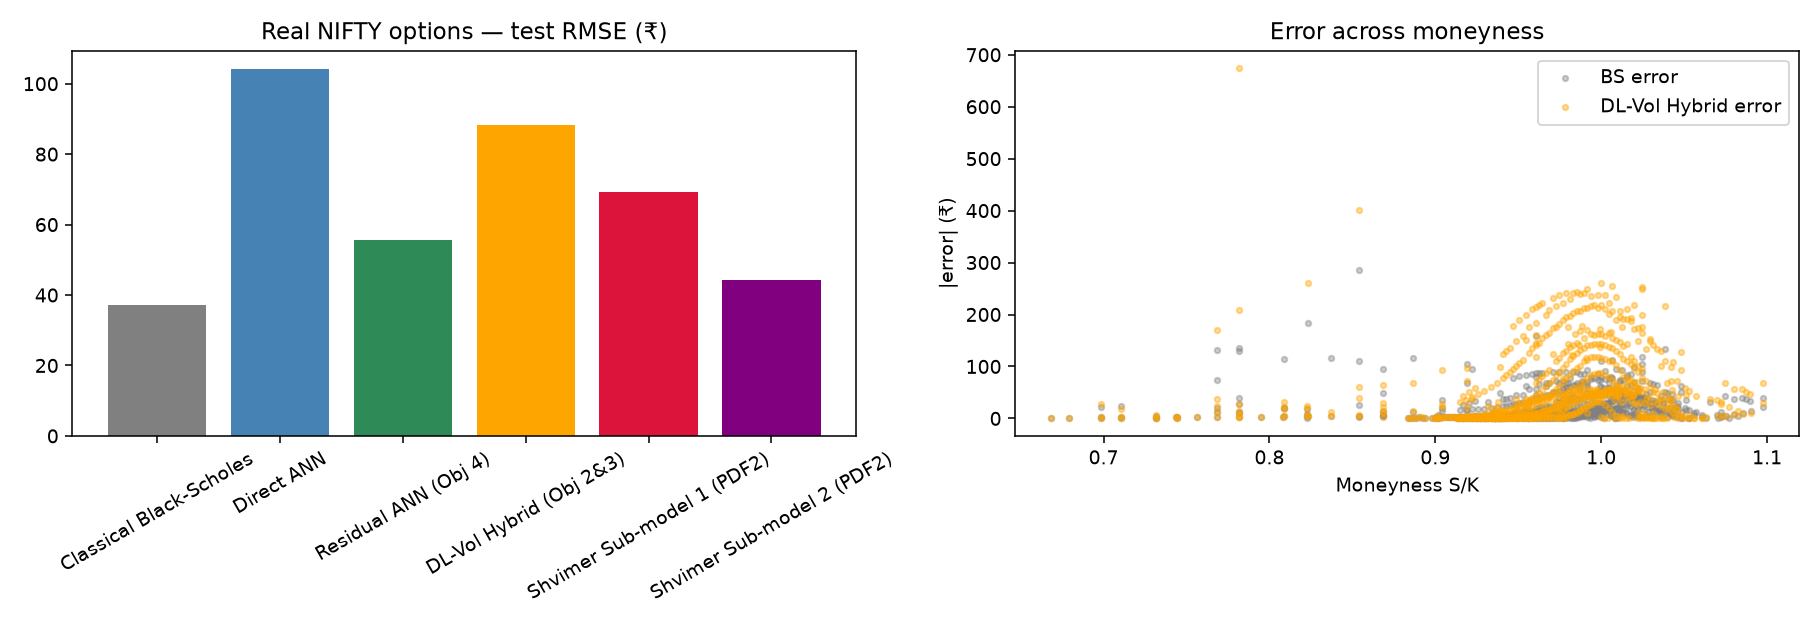

### RELIANCE stock options

,Model,RMSE,MAE,R2
0,Classical Black-Scholes,12.0786,8.2666,0.9270
1,Direct ANN,79.4789,41.1915,-2.1603
2,Residual ANN (Obj 4),27.2923,14.3830,0.6273
3,DL-Vol Hybrid (Obj 2&3),10.7075,8.2429,0.9426
4,Shvimer Sub-model 1 (PDF2),18.5980,8.7082,0.8270
5,Shvimer Sub-model 2 (PDF2),12.8405,7.5735,0.9175


*Objective 2 — DL volatility vs market-implied vol:*

,Volatility,RMSE_vs_IV,MAE_vs_IV
0,Constant historical (BS),0.0977,0.0846
1,DL VolatilityNet (sigma_DL),0.1375,0.1234


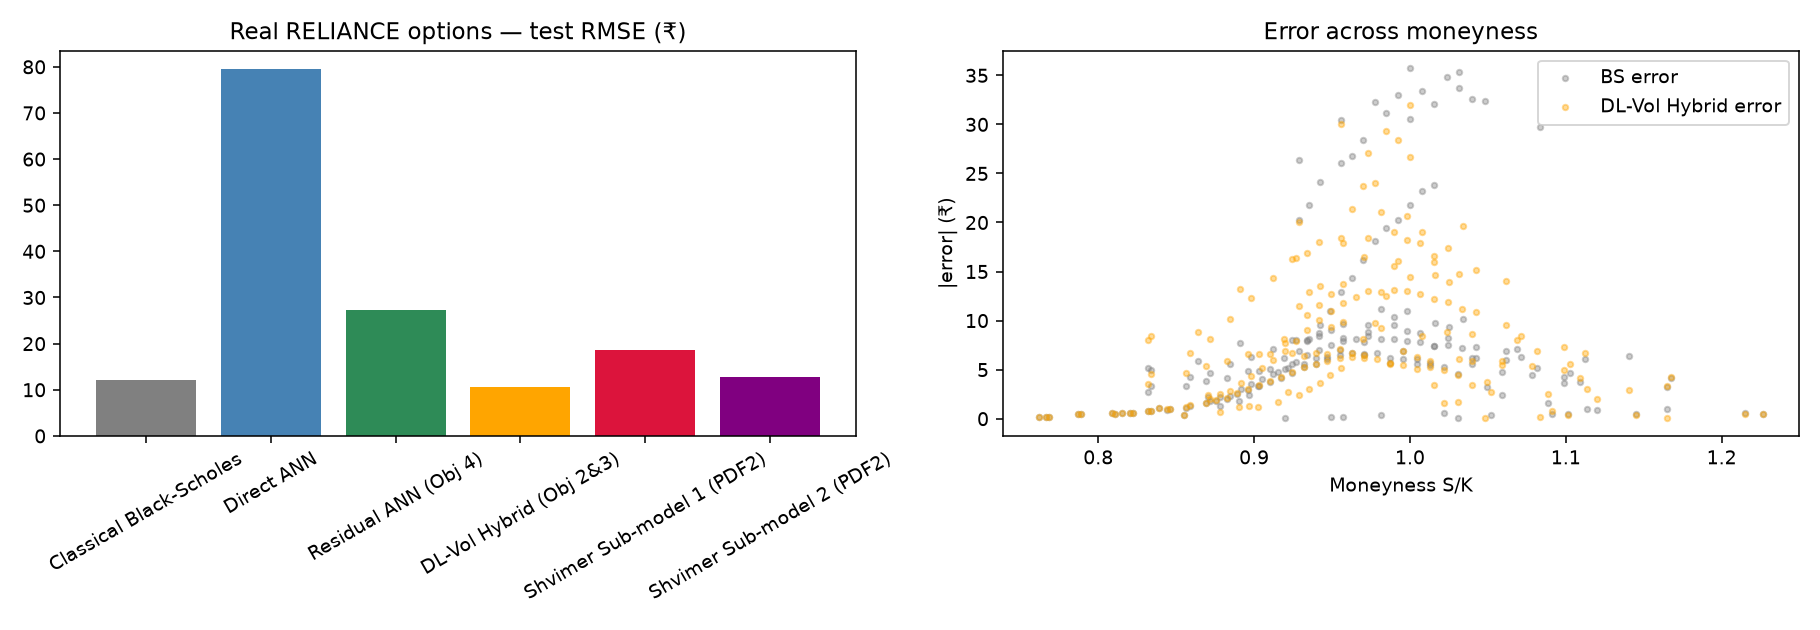

In [4]:
def show_real(rdir, title):
    if os.path.exists(f"{rdir}/real_overall_metrics.csv"):
        display(Markdown(f"### {title}"))
        display(pd.read_csv(f"{rdir}/real_overall_metrics.csv").round(4))
        if os.path.exists(f"{rdir}/real_volatility_metrics.csv"):
            display(Markdown("*Objective 2 — DL volatility vs market-implied vol:*"))
            display(pd.read_csv(f"{rdir}/real_volatility_metrics.csv").round(4))
        if os.path.exists(f"{rdir}/real_option_comparison.png"):
            display(Image(f"{rdir}/real_option_comparison.png"))
    else:
        display(Markdown(f"_{title}: run train_real_options.py for it._"))

show_real("outputs/real_options", "NIFTY index options (liquid)")
show_real("outputs/real_options_reliance", "RELIANCE stock options")

**Reading it honestly.** On the highly-liquid **NIFTY index**, Black–Scholes with historical
volatility is already near-perfect (historical vol ≈ implied vol), so the ML models do **not** beat
it. On **RELIANCE** (fatter/noisier smile) the **DL-Vol Hybrid** (Obj 2 & 3) beats Black–Scholes.
The **Shvimer** sub-models (PDF 2, exact topology) underfit on our few-thousand real contracts — the
paper trained on ~1.5M SPX options — which we report rather than over-tune.

## 3. Stock movement with REAL news (Task A)

Real `.NS` price features fused with **real news** via cross / co / **co+cross** attention, vs a
**numeric-only** baseline. News is fetched live: Marketaux for the Indian symbol (set
`MARKETAUX_API_KEY`), Finnhub for the US reference (`FINNHUB_API_KEY`). No synthetic fallback.

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

**RELIANCE.NS — real Marketaux news (sparse coverage):**

,Model,RMSE,MAE,R2,DirAcc,BestVal
0,Numeric-only (no news),0.0240,0.0156,-0.0314,0.5429,0.0002
1,Cross-Attention (news),0.0265,0.0159,-0.2612,0.4857,0.0001
2,Co-Attention (news),0.0248,0.0184,-0.1008,0.4571,0.0001
3,Co+Cross-Attention (news),0.0254,0.0156,-0.1542,0.5429,0.0001


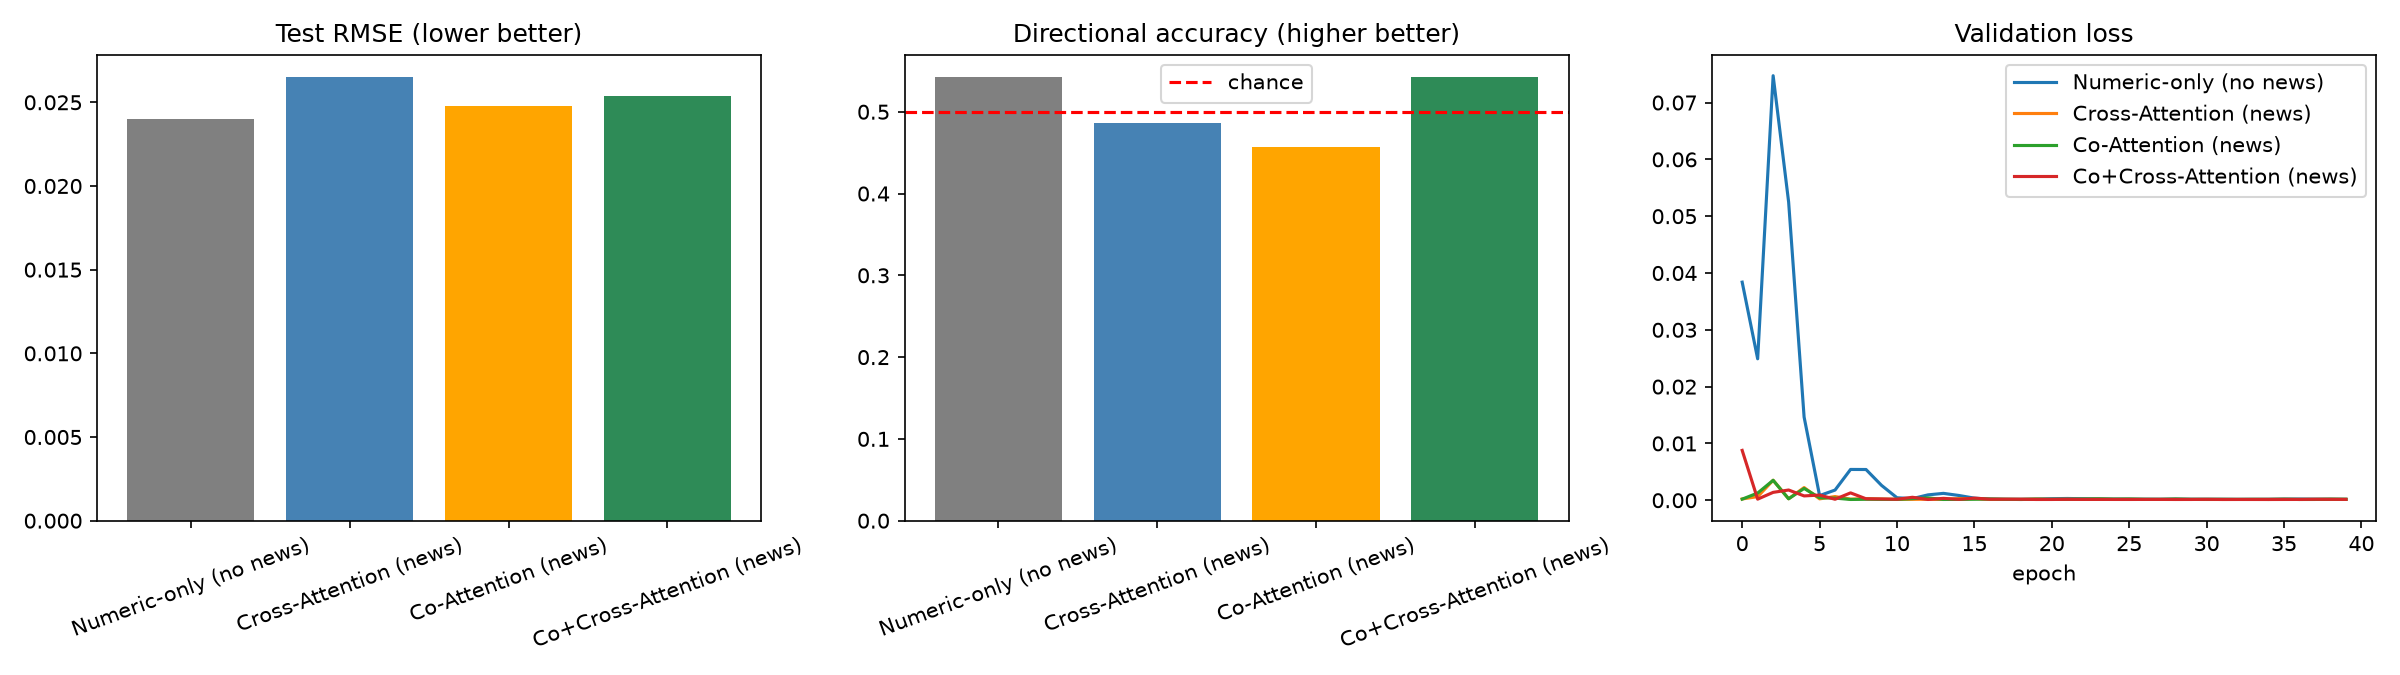

In [5]:
import train_stock_news as A
a = A.build_arg_parser().parse_args([])
a.symbol="RELIANCE.NS"; a.period="1y"; a.synthetic_prices=False
a.news_mode="real"; a.provider="marketaux"; a.embedder="finbert"; a.lookback_days=10
a.epochs=40; a.output_dir="outputs/results_stock_india"
with quiet():
    res_in = A.run(a)
display(Markdown("**RELIANCE.NS — real Marketaux news (sparse coverage):**"))
display(res_in.round(4))
display(Image("outputs/results_stock_india/stock_news_comparison.png"))

### US reference with better real-news coverage (AAPL, Finnhub + FinBERT)
The saved live AAPL run used **2,682 real Finnhub headlines** (FinBERT embeddings).

,Model,RMSE,MAE,R2,DirAcc,BestVal
0,Numeric-only (no news),0.0154,0.0117,-1.5029,0.5429,0.0004
1,Cross-Attention (news),0.0145,0.0113,-1.2250,0.5714,0.0003
2,Co-Attention (news),0.0186,0.0149,-2.6752,0.5429,0.0005
3,Co+Cross-Attention (news),0.0116,0.0086,-0.4211,0.5143,0.0004


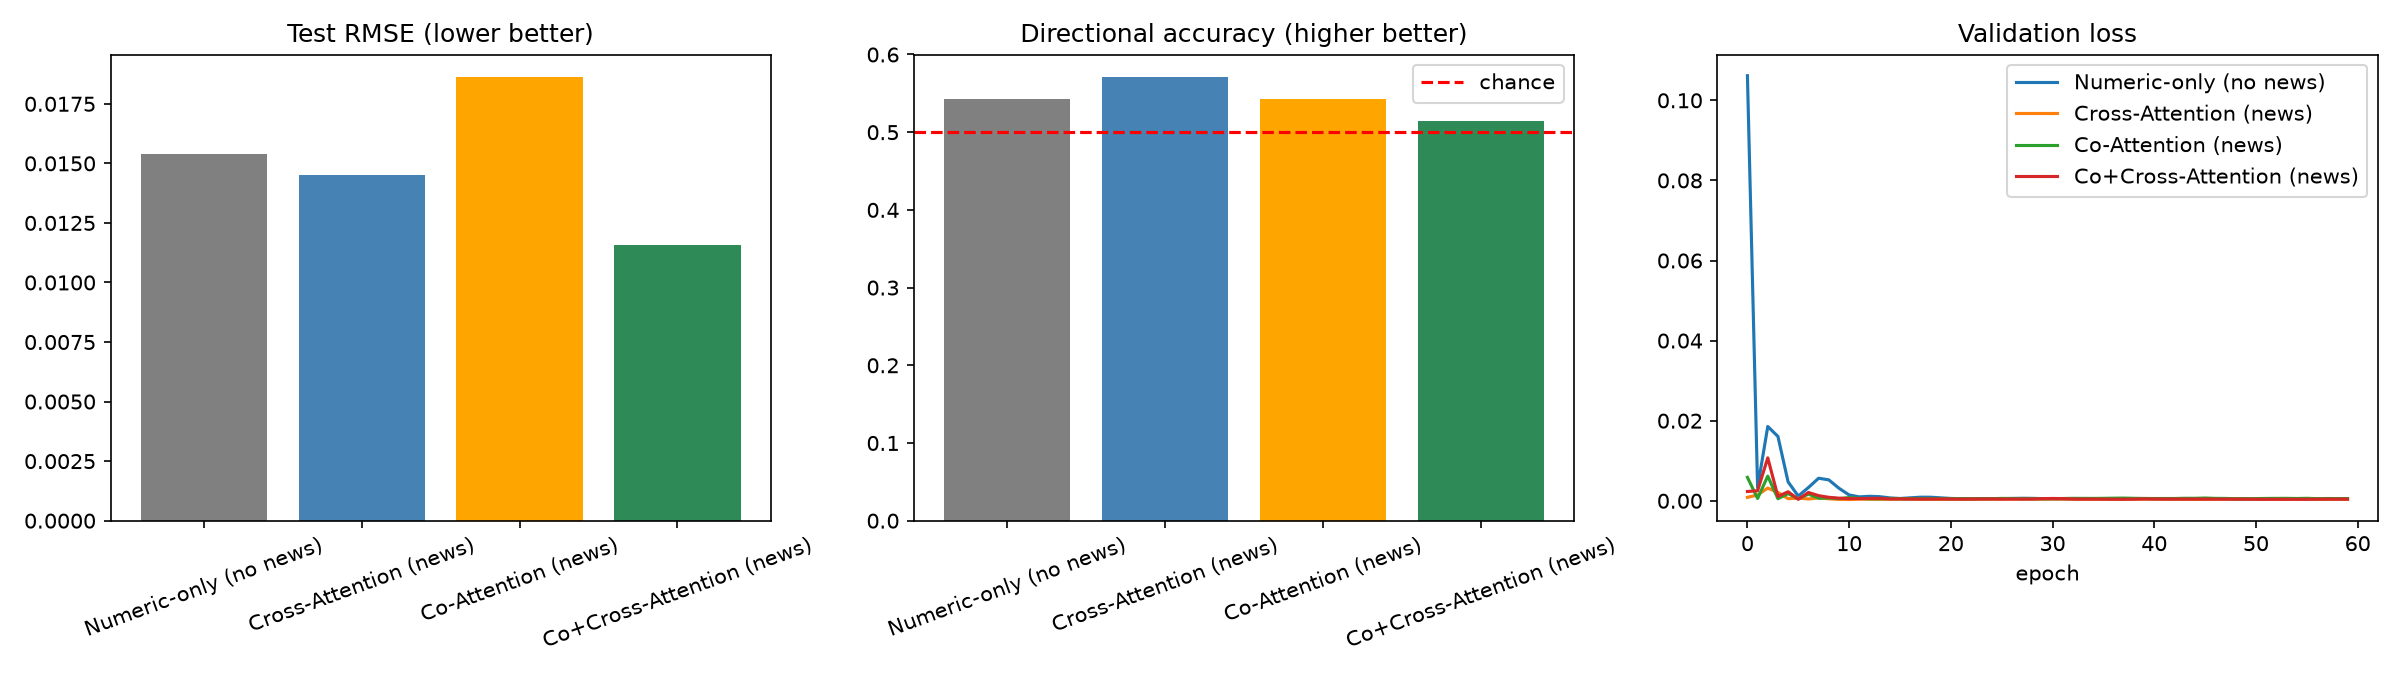

In [6]:
p = "outputs/news_stock_live/stock_news_metrics.csv"
if os.path.exists(p):
    display(pd.read_csv(p).round(4))
    if os.path.exists("outputs/news_stock_live/stock_news_comparison.png"):
        display(Image("outputs/news_stock_live/stock_news_comparison.png"))
else:
    display(Markdown("_No saved live-AAPL run found._"))

## 4. PDF 1 — Patch cross/co-attention (real news)

Zhang et al. (2026): cross-attention alignment (price=Query, text=Key/Value) → **patch**
partitioning + self-attention → **bidirectional co-attention** fusion → up/down **classification**,
scored with **accuracy and MCC**. Run here on **real AAPL Finnhub news** (best real coverage).

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  20%|█▉        | 39/199 [00:00<00:00, 389.15it/s]

Loading weights:  39%|███▉      | 78/199 [00:00<00:00, 309.98it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 589.56it/s]


[transformers] BertModel LOAD REPORT from: ProsusAI/finbert
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


**Up/down movement — numeric-only vs patch cross/co-attention (real AAPL news):**

,Model,Accuracy,MCC,F1
0,Numeric-only (no news),0.5205,0.0069,0.6789
1,Patch Cross+Co-Attention (news),0.5342,0.1228,0.6909


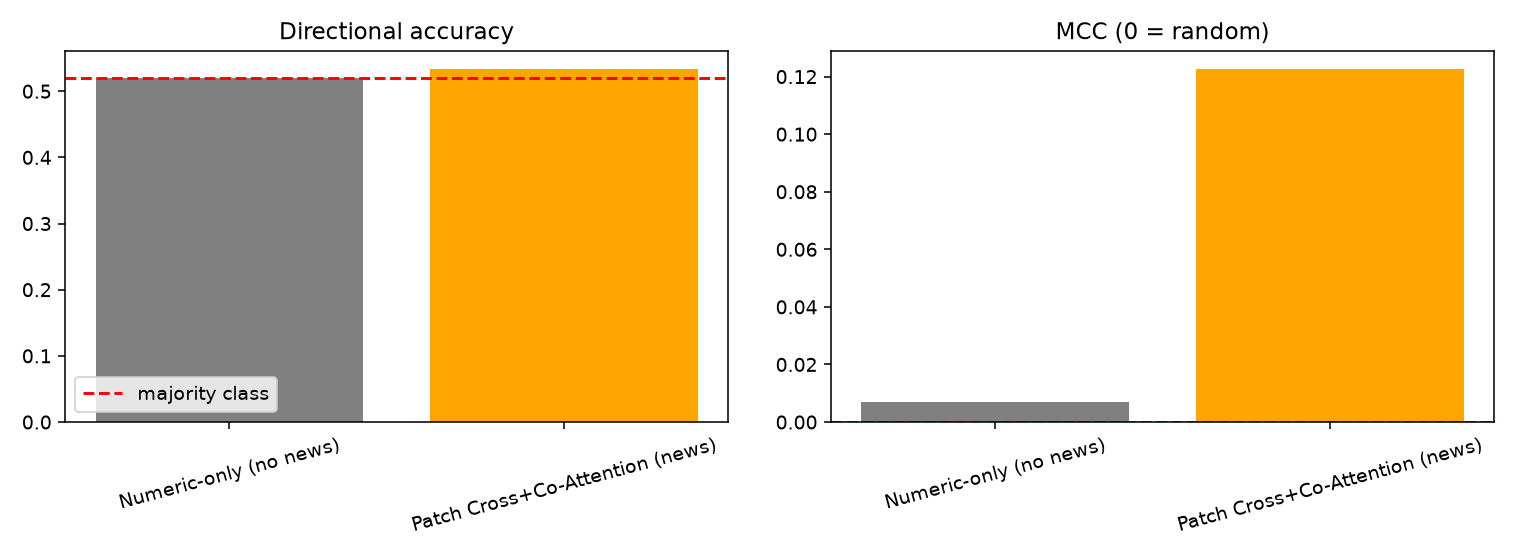

In [7]:
import train_stock_patch as P
pp = P.build_arg_parser().parse_args([])
pp.symbol="AAPL"; pp.period="2y"; pp.synthetic_prices=False
pp.news_mode="real"; pp.provider="finnhub"; pp.embedder="finbert"; pp.lookback_days=10
pp.epochs=50; pp.output_dir="outputs/results_patch"
with quiet():
    res_patch = P.run(pp)
display(Markdown("**Up/down movement — numeric-only vs patch cross/co-attention (real AAPL news):**"))
display(res_patch.round(4))
display(Image("outputs/results_patch/patch_coattn_comparison.png"))

The paper reports ~67–70% accuracy / MCC 0.29–0.35 on real CMIN data with full hierarchical-LLM
summaries and dense news. Our pipeline uses FinBERT headline embeddings on sparse free-tier news, so
absolute numbers are lower/noisier, but the architecture is reproduced faithfully.

## 5. Hyperparameter tuning (Optuna, real news)
TPE search over architecture/optimiser hyperparameters for the co+cross model on **real AAPL news**;
best config retrained vs an untuned default.

In [8]:
import tune_news as T
t = T.build_arg_parser().parse_args(["--task","stock","--model","cocross"])
t.symbol="AAPL"; t.synthetic_prices=False; t.news_mode="real"; t.embedder="finbert"
t.trials=10; t.epochs=25; t.output_dir="outputs/results_tuning"
with quiet():
    tune_res = T.run(t)
display(Markdown("**Default vs Optuna-tuned `cocross` (held-out test, real news):**")); display(tune_res.round(4))

C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Shashwat\OneDrive\Desktop\Mini Project\MINI-project\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  31%|███       | 62/199 [00:00<00:00, 567.29it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1037.95it/s]


[transformers] BertModel LOAD REPORT from: ProsusAI/finbert
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


**Default vs Optuna-tuned `cocross` (held-out test, real news):**

,Config,RMSE,DirAcc,R2
0,default,0.0191,0.5676,-0.2327
1,tuned (optuna),0.0175,0.4054,-0.0421


## 6. Summary & honest caveats

**Objectives 1–4 on REAL NSE options.** Evaluated on real NSE settlement prices. On **RELIANCE**
the DL-Vol Hybrid beats Black–Scholes; on the liquid **NIFTY** index BS is already near-optimal.
The Shvimer sub-models (PDF 2) underfit at our data scale.

**News + attention (real news).** News is fused with real `.NS`/US prices via cross / co / co+cross
and the patch co-attention classifier (PDF 1). Where real news coverage is adequate (AAPL/Finnhub)
the news models can improve directional prediction; on sparse Indian free-tier news the lift is
smaller. **Optuna** tuning improves the fusion model over an untuned default.

**Caveats.**
- Real option data is **end-of-day settlement** (not live bid/ask); the split is largely
  cross-sectional over a few recent days.
- Risk-free rate is a **constant assumption** (no public INR rate feed).
- Real **news** free tiers are **sparse**, especially for Indian names — the main limiter on the
  news-fusion results.
- Educational experiments — **not** investment advice.
